# Homework 1 — Linear algebra and data processing

Original joint coursework: **Raha Sajed (credited as Fatemeh Sajed) and Aylar Rahimzadeh**. Post-course corrections: **Raha Sajed (`raha-sajed`)**.

This notebook follows [the assignment](AI4032_HW1.pdf). Linear algebra and the CWRU signal exercise are completed below. The Iris section remains to be completed.

# 1. Linear algebra

## I-a. Matrix dimensions

The assignment gives $A\in\mathbb{R}^{2\times3}$ and $B\in\mathbb{R}^{4\times2}$.
A product $(m\times k)(k\times p)$ is defined only when its inner dimensions agree; its shape is $m\times p$. A transpose swaps rows and columns.

| Expression | Dimension check | Answer |
| --- | --- | --- |
| $BA$ | $(4\times2)(2\times3)$ | Defined: $4\times3$ |
| $B^T$ | Transpose of $4\times2$ | $2\times4$ |
| $B^TA$ | $(2\times4)(2\times3)$; $4\ne2$ | Undefined |
| $A^TB$ | $(3\times2)(4\times2)$; $2\ne4$ | Undefined |

**Correction:** reshaping a matrix to make a product run changes the matrix and the problem. The undefined products must remain undefined.

## I-b. Compute the defined expressions

For $i=1,\ldots,4$ and $j=1,\ldots,3$,
$$(BA)_{ij}=b_{i1}a_{1j}+b_{i2}a_{2j}.$$

$$BA=\begin{bmatrix}
b_{11}a_{11}+b_{12}a_{21}&b_{11}a_{12}+b_{12}a_{22}&b_{11}a_{13}+b_{12}a_{23}\\
b_{21}a_{11}+b_{22}a_{21}&b_{21}a_{12}+b_{22}a_{22}&b_{21}a_{13}+b_{22}a_{23}\\
b_{31}a_{11}+b_{32}a_{21}&b_{31}a_{12}+b_{32}a_{22}&b_{31}a_{13}+b_{32}a_{23}\\
b_{41}a_{11}+b_{42}a_{21}&b_{41}a_{12}+b_{42}a_{22}&b_{41}a_{13}+b_{42}a_{23}
\end{bmatrix}.$$

$$B^T=\begin{bmatrix}b_{11}&b_{21}&b_{31}&b_{41}\\b_{12}&b_{22}&b_{32}&b_{42}\end{bmatrix}.$$

There is no value to calculate for $B^TA$ or $A^TB$ with the given matrices. The numerical example below uses the same illustrative values as the original report; the symbolic answer above applies to arbitrary entries.

In [1]:
import numpy as np

A = np.array([[1, 2, 3], [4, 5, 6]])
B = np.array([[1, 2], [3, 1], [4, 5], [6, 7]])
BA = B @ A
BT = B.T
np.testing.assert_array_equal(BA, [[9, 12, 15], [7, 11, 15], [24, 33, 42], [34, 47, 60]])
np.testing.assert_array_equal(BT, [[1, 3, 4, 6], [2, 1, 5, 7]])
assert BA.shape == (4, 3) and BT.shape == (2, 4)
print("BA =\n", BA)
print("B transpose =\n", BT)
for name, left, right in [("B.T @ A", B.T, A), ("A.T @ B", A.T, B)]:
    try:
        left @ right
    except ValueError:
        print(f"{name}: undefined ({left.shape[1]} != {right.shape[0]})")
    else:
        raise AssertionError(f"{name} should be undefined")

BA =
 [[ 9 12 15]
 [ 7 11 15]
 [24 33 42]
 [34 47 60]]
B transpose =
 [[1 3 4 6]
 [2 1 5 7]]
B.T @ A: undefined (4 != 2)
A.T @ B: undefined (2 != 4)


## II-a. Row-vector and matrix predictions

A sample $x^{(i)}=[x_1^{(i)}\;x_2^{(i)}]$ has shape $1\times2$, and
$\theta=[\theta_1\;\theta_2]^T$ has shape $2\times1$. Therefore
$$x^{(i)}\theta=x_1^{(i)}\theta_1+x_2^{(i)}\theta_2\in\mathbb{R}^{1\times1}.$$

Stacking $n$ samples gives $X\in\mathbb{R}^{n\times2}$ and
$$X\theta=\begin{bmatrix}x_1^{(1)}\theta_1+x_2^{(1)}\theta_2\\\vdots\\x_1^{(n)}\theta_1+x_2^{(n)}\theta_2\end{bmatrix}\in\mathbb{R}^{n\times1}.$$

In NumPy, `X[i:i+1]` keeps a sample as a row matrix; `X[i]` produces a one-dimensional array. Column-shaped targets also prevent unintended broadcasting.

In [2]:
X = np.array([[1., 1.], [1., 2.], [1., 3.]])
theta = np.array([[0.5], [1.5]])
y = np.array([[2.], [4.], [6.]])
x_i = X[0:1]
assert x_i.shape == (1, 2) and theta.shape == (2, 1)
assert (x_i @ theta).shape == (1, 1)
assert (X @ theta).shape == (3, 1)
print("One sample prediction:", x_i @ theta, "shape:", (x_i @ theta).shape)
print("All predictions:\n", X @ theta, "shape:", (X @ theta).shape)

One sample prediction: [[2.]] shape: (1, 1)
All predictions:
 [[2. ]
 [3.5]
 [5. ]] shape: (3, 1)


## II-b. Vector form of the loss and its gradient

Let $y\in\mathbb{R}^{n\times1}$ and $r=X\theta-y$. The assignment uses the **sum** of squared errors:
$$J(\theta)=\sum_{i=1}^{n}(x^{(i)}\theta-y^{(i)})^2=r^Tr=(X\theta-y)^T(X\theta-y).$$
This is a scalar ($1\times1$). Expanding it gives
$$J=\theta^TX^TX\theta-2\theta^TX^Ty+y^Ty.$$
Since $X^TX$ is symmetric and $X,y$ do not depend on $\theta$,
$$\boxed{\nabla_\theta J=2X^TX\theta-2X^Ty=2X^T(X\theta-y)}\in\mathbb{R}^{2\times1}.$$

Equivalently, for $j\in\{1,2\}$,
$$\frac{\partial J}{\partial\theta_j}=2\sum_{i=1}^{n}x_j^{(i)}\bigl(x^{(i)}\theta-y^{(i)}\bigr).$$

**Correction:** the gradient must be evaluated, not left as an unevaluated derivative. There is no $1/n$ in this assignment's loss. Using MSE instead would divide this gradient by $n$; using $J/(2n)$ would give $X^Tr/n$.

In [3]:
def squared_error_and_gradient(X, theta, y):
    """Sum of squared errors; use explicit column vectors to avoid broadcasting."""
    X, theta, y = (np.asarray(value, dtype=float) for value in (X, theta, y))
    if X.ndim != 2 or theta.shape != (X.shape[1], 1) or y.shape != (X.shape[0], 1):
        raise ValueError("Expected X: (n, p), theta: (p, 1), y: (n, 1)")
    residual = X @ theta - y
    return float((residual.T @ residual).item()), 2 * X.T @ residual

J, gradient = squared_error_and_gradient(X, theta, y)
np.testing.assert_allclose(J, 1.25)
np.testing.assert_allclose(gradient, [[-3.], [-8.]])
np.testing.assert_allclose(J, sum(float((row @ theta).item() - target.item()) ** 2 for row, target in zip(X, y)))
print("J =", J)
print("Gradient =\n", gradient, "shape:", gradient.shape)

J = 1.25
Gradient =
 [[-3.]
 [-8.]] shape: (2, 1)


## Numerical verification

A central finite-difference approximation checks each partial derivative independently of the matrix-gradient formula. We test several data sizes and parameter values, plus a malformed target shape that would otherwise broadcast silently.

In [4]:
rng = np.random.default_rng(42)
max_absolute_error = 0.0
for n in (1, 3, 10):
    X_check = rng.normal(size=(n, 2))
    theta_check = rng.normal(size=(2, 1))
    y_check = rng.normal(size=(n, 1))
    loss, analytic = squared_error_and_gradient(X_check, theta_check, y_check)
    numeric = np.zeros_like(theta_check)
    epsilon = 1e-6
    for j in range(2):
        step = np.zeros_like(theta_check)
        step[j, 0] = epsilon
        plus, _ = squared_error_and_gradient(X_check, theta_check + step, y_check)
        minus, _ = squared_error_and_gradient(X_check, theta_check - step, y_check)
        numeric[j, 0] = (plus - minus) / (2 * epsilon)
    np.testing.assert_allclose(analytic, numeric, rtol=1e-6, atol=1e-6)
    max_absolute_error = max(max_absolute_error, float(np.max(np.abs(analytic - numeric))))
try:
    squared_error_and_gradient(X, theta, y.ravel())
except ValueError:
    pass
else:
    raise AssertionError("A one-dimensional target must be rejected")
print("All dimension, product, loss and gradient checks passed.")
print(f"Maximum absolute finite-difference error: {max_absolute_error:.2e}")

All dimension, product, loss and gradient checks passed.
Maximum absolute finite-difference error: 8.76e-10


# 2. Data processing — CWRU signal

## I-a. Read the MAT file and identify its contents

The input is a MATLAB `.mat` file. `scipy.io.loadmat` returns a dictionary: `__header__`, `__version__` and `__globals__` describe the MAT container; the other entries hold measurements. `DE` and `FE` identify drive-end and fan-end accelerometer signals; `RPM` is motor speed. We select `X201_DE_time` without changing its samples.

The assignment specifies **48 kHz**. The [CWRU 48k table](https://engineering.case.edu/bearingdatacenter/48k-drive-end-bearing-fault-data) links `201.mat` as the outer-race, 0.014-inch, zero-load case. [CWRU variable naming](https://engineering.case.edu/bearingdatacenter/download-data-file) explains the channel names.

In [5]:
from pathlib import Path
import sys
import pandas as pd
from scipy.io import loadmat
from IPython.display import display, Image
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "HomeWork1" / "201.mat").is_file())
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
from HomeWork1.signal_analysis import (
    HERE, run, compute_spectrum, segment_signal, extract_features,
    signal_statistics, time_window,
)
payload = loadmat(HERE / "201.mat")
print("Container type:", type(payload).__name__)
display(pd.DataFrame([
    {"field": name, "type": type(value).__name__, "shape": getattr(value, "shape", None)}
    for name, value in payload.items()
]))
signal = payload["X201_DE_time"].reshape(-1)
fs = 48_000.
print("Selected channel:", "X201_DE_time", "samples:", len(signal))
print("Recorded motor speed (RPM):", int(payload["X201RPM"].item()))

Container type: dict
Selected channel: X201_DE_time samples: 245140
Recorded motor speed (RPM): 1796


,field,type,shape
0,__header__,bytes,None
1,__version__,str,None
2,__globals__,list,None
3,X201_DE_time,ndarray,"(245140, 1)"
4,X201_FE_time,ndarray,"(245140, 1)"
5,X201RPM,ndarray,"(1, 1)"


## I-b. Plot the signal in seconds

Use $t_k=k/f_s$ with $f_s=48,000$ Hz. Plot the entire recording, then the requested interval $[2.00,2.01)$ seconds. The interval is half-open to avoid duplicating a boundary sample. We retain every original sample; taking every second sample without adjusting the time vector would distort the time axis.

{
  "n_samples": 245140,
  "sampling_rate_hz": 48000.0,
  "zoom_samples": 480,
  "n_windows": 3829,
  "dominant_frequency_hz": 0.19580647793097825,
  "all_features_finite": true
}
Recording duration: 5.107083 seconds; zoom samples: 480


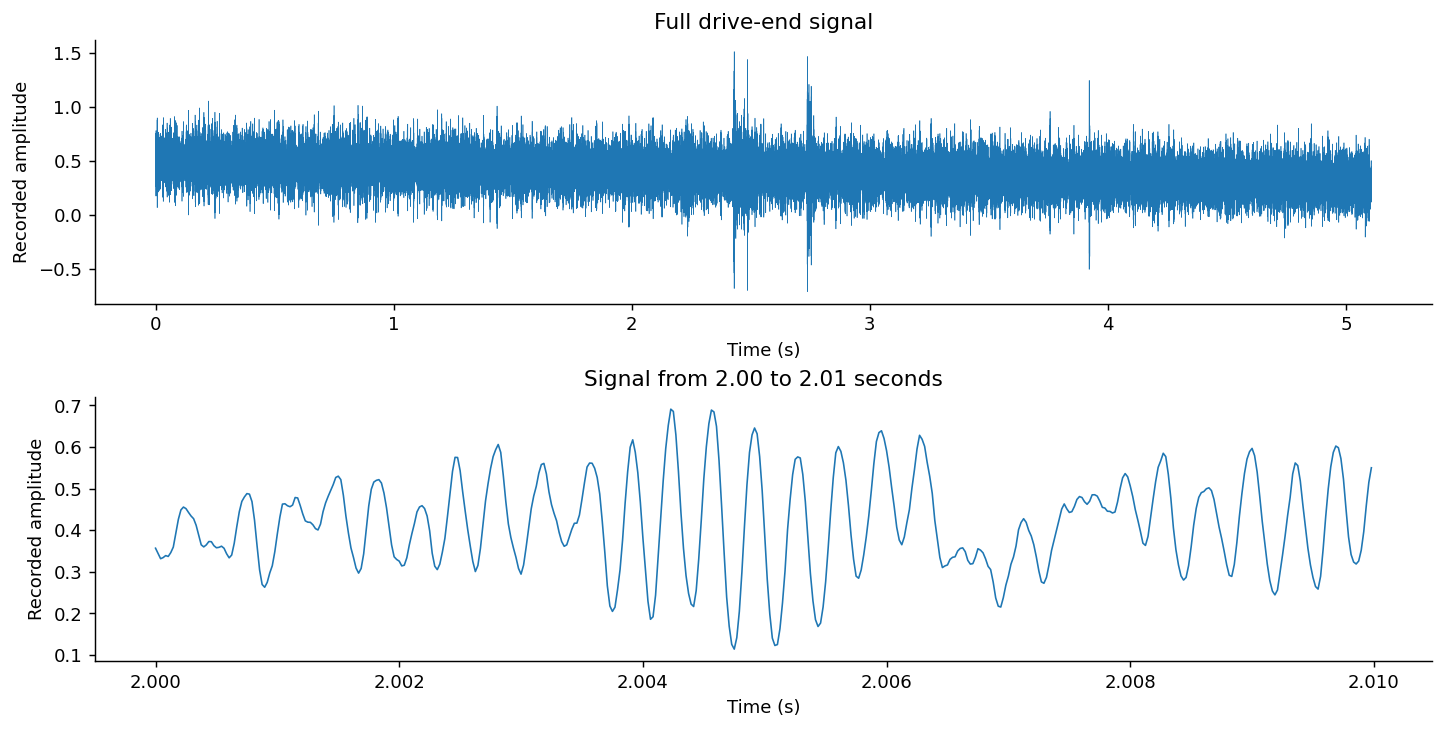

In [6]:
import io
import matplotlib.pyplot as plt

def show_figure(fig):
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", dpi=130, bbox_inches="tight")
    display(Image(data=buffer.getvalue()))
    plt.close(fig)

summary = run(HERE / "201.mat", HERE / "results", sampling_rate=fs)
time = np.arange(len(signal)) / fs
zoom_time, zoom_signal = time_window(signal, fs, 2., 2.01)
assert len(zoom_signal) == 480
fig, axes = plt.subplots(2, 1, figsize=(11, 5.5), layout="constrained")
axes[0].plot(time, signal, linewidth=.35)
axes[0].set(title="Full drive-end signal", xlabel="Time (s)", ylabel="Recorded amplitude")
axes[1].plot(zoom_time, zoom_signal, linewidth=.9)
axes[1].set(title="Signal from 2.00 to 2.01 seconds", xlabel="Time (s)", ylabel="Recorded amplitude")
show_figure(fig)
print(f"Recording duration: {len(signal)/fs:.6f} seconds; zoom samples: {len(zoom_signal)}")

## I-c. Frequency spectrum and dominant frequency

`compute_spectrum(signal, fs)` subtracts the global mean for the FFT, calculates a one-sided amplitude spectrum and finds the largest non-DC bin. Positive-frequency amplitudes are doubled except the Nyquist bin for an even-length signal. The frequency spacing is $\Delta f=f_s/N$; the reported peak is a bin estimate, not a sub-bin fitted frequency.

Mean removal applies to the FFT only. Segments and statistical features below use the original signal.

Dominant non-DC FFT bin: 0.196 Hz
FFT bin spacing: 0.195806 Hz


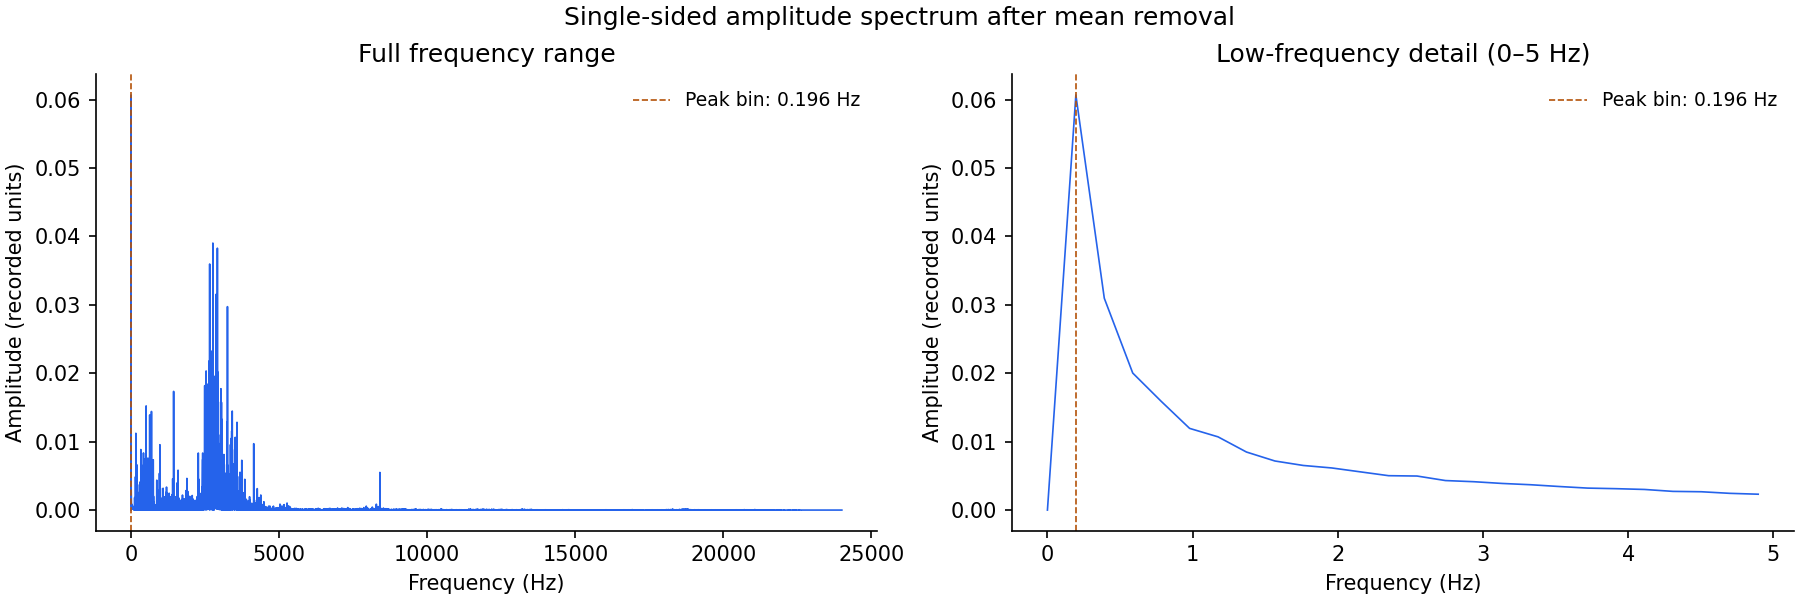

In [7]:
frequency, amplitude, dominant_hz = compute_spectrum(signal, fs)
assert dominant_hz == summary["dominant_frequency_hz"]
print(f"Dominant non-DC FFT bin: {dominant_hz:.3f} Hz")
print(f"FFT bin spacing: {fs/len(signal):.6f} Hz")
display(Image(filename=str(HERE / "results/frequency_spectrum.png")))

## I-d. Divide the signal into windows

Use 128 samples per window and choose 64 samples of overlap. Each row of the NumPy array is one window; the hop is 64 samples. Complete windows number
$$1+\left\lfloor\frac{N-128}{64}\right\rfloor=3829.$$
The final 20 samples cannot form another complete window and are left out.

In [8]:
windows, starts = segment_signal(signal, length=128, overlap=64)
assert windows.shape == (3829, 128)
assert np.array_equal(windows[0], signal[:128])
assert np.array_equal(windows[1], signal[64:192])
print("Window array shape:", windows.shape)
print("Unused tail samples:", len(signal) - (starts[-1] + 128))

Window array shape: (3829, 128)
Unused tail samples: 20


## I-e. DataFrame and ten segment overlays

Create a DataFrame with one segment per row. Select zero-based rows 13, 26, ..., 130: ten positive multiples of 13. A single `for` loop plots these rows with different colors and labels. Time within a segment is measured from that segment's start.

DataFrame shape: (3829, 128) selected rows: [13, 26, 39, 52, 65, 78, 91, 104, 117, 130]


,0,1,2,3,4,5,6,7
0,0.609157,0.675914,0.730988,0.755605,0.736204,0.676748,0.600186,0.512568
1,0.334202,0.391154,0.455199,0.511316,0.550536,0.565556,0.549702,0.515489
2,0.399290,0.426827,0.461666,0.506518,0.565348,0.617919,0.673202,0.701991


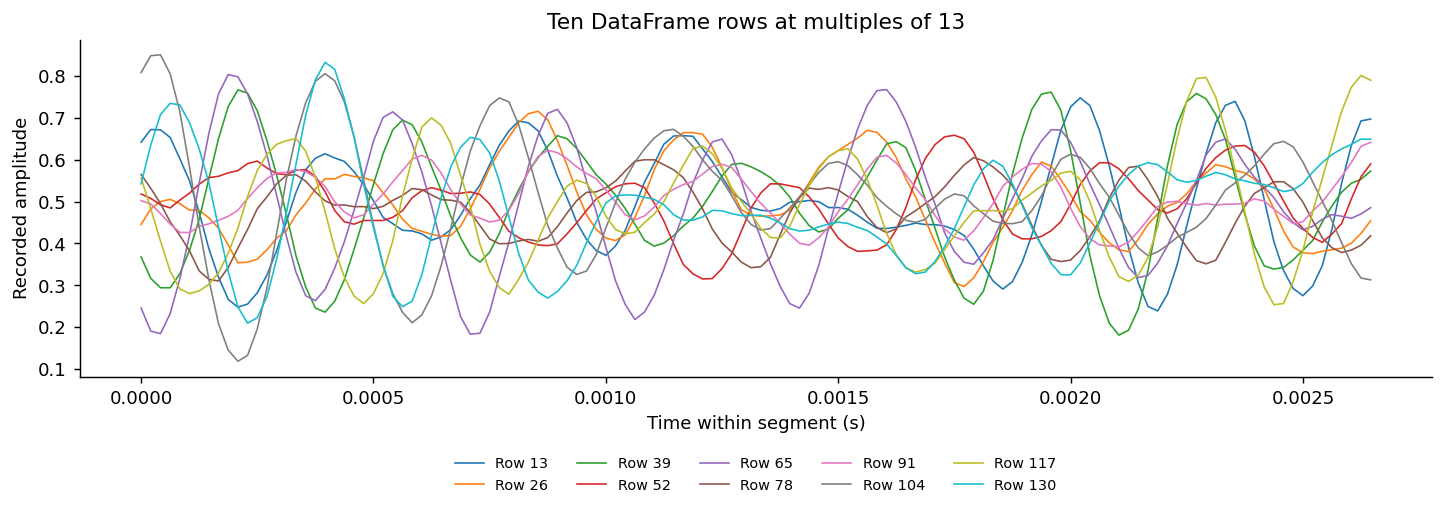

In [9]:
segments = pd.DataFrame(windows)
display(segments.iloc[:3, :8])
selected_rows = np.arange(13, 131, 13)
fig, ax = plt.subplots(figsize=(11, 3.8), layout="constrained")
colors = plt.get_cmap("tab10")
for color_index, row_index in enumerate(selected_rows):
    ax.plot(np.arange(128)/fs, segments.iloc[row_index].to_numpy(),
            color=colors(color_index), label=f"Row {row_index}", linewidth=.9)
ax.set(title="Ten DataFrame rows at multiples of 13", xlabel="Time within segment (s)", ylabel="Recorded amplitude")
ax.legend(ncol=5, fontsize=8, frameon=False, loc="upper center", bbox_to_anchor=(.5, -.2))
show_figure(fig)
print("DataFrame shape:", segments.shape, "selected rows:", selected_rows.tolist())

## I-f. Extract features and export CSV

For one signal window $s$ of length $L$, `signal_statistics` returns
$$\mu=\frac1L\sum_k s_k,\qquad \sigma=\sqrt{\frac1L\sum_k(s_k-\mu)^2},\qquad \mathrm{RMS}=\sqrt{\frac1L\sum_k s_k^2}.$$

We use population standard deviation (`ddof=0`) and apply the function to every original, uncentered window. `segment_features.csv` contains **only** the feature columns `mean`, `std`, `rms`, with a header and without a sample/index column.

In [10]:
features = extract_features(windows)
features.to_csv(HERE / "results/segment_features.csv", index=False, float_format="%.10g")
exported = pd.read_csv(HERE / "results/segment_features.csv")
assert exported.shape == (3829, 3)
assert exported.columns.tolist() == ["mean", "std", "rms"]
np.testing.assert_allclose(exported.to_numpy(), features.to_numpy(), rtol=1e-8, atol=1e-10)
np.testing.assert_allclose(features.rms**2, features["std"]**2 + features["mean"]**2)
display(features.head())
display(features.describe())
print("CSV verified:", exported.shape, "columns:", exported.columns.tolist())

CSV verified: (3829, 3) columns: ['mean', 'std', 'rms']


,mean,std,rms
0,0.498770,0.151039,0.521138
1,0.498372,0.146235,0.519384
2,0.506720,0.113735,0.519327
3,0.504900,0.094127,0.513599
4,0.494852,0.191406,0.530579


,mean,std,rms
count,3829.000000,3829.000000,3829.000000
mean,0.396057,0.132965,0.420068
std,0.056368,0.044321,0.056788
min,0.283683,0.046022,0.296872
25%,0.347213,0.105378,0.373306
50%,0.392746,0.126204,0.418054
75%,0.443008,0.152206,0.464570
max,0.521102,0.649391,0.751479


## Signal results

The largest non-DC FFT bin is approximately **0.196 Hz**, equal to the bin spacing for this approximately 5.107-second recording. This indicates strong slow variation in the recording, not an identified bearing-fault frequency. The low-frequency panel shows this peak clearly.

The notebook covers MAT loading, field descriptions, full and zoomed time plots, FFT and its dominant frequency, 128-sample segmentation, the required DataFrame overlay, and three-feature CSV export. The raw recording is preserved. This is descriptive signal processing; the spectral peak alone is not a bearing-fault diagnosis.

# 3. Iris

To be completed in the next step.